# Exploratory Data Analysis

Dataset: Kaggle *Personal Key Indicators of Heart Disease* (2022, with NaNs), a subset of the CDC BRFSS phone survey. Each row is one survey respondent.

In [2]:
import pandas as pd

pd.set_option("display.max_columns", None)

df = pd.read_csv("data/raw/heart_2022_with_nans.csv.zip")

## 1. Structure

### Size

In [3]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")

Rows: 445,132
Columns: 40
Memory: 860 MB


### Columns and types

In [4]:
numeric_cols = df.select_dtypes("number").columns.tolist()
categorical_cols = df.columns.difference(numeric_cols, sort=False).tolist()

print(f"Numeric ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical ({len(categorical_cols)}): {categorical_cols}")

Numeric (6): ['PhysicalHealthDays', 'MentalHealthDays', 'SleepHours', 'HeightInMeters', 'WeightInKilograms', 'BMI']
Categorical (34): ['State', 'Sex', 'GeneralHealth', 'LastCheckupTime', 'PhysicalActivities', 'RemovedTeeth', 'HadHeartAttack', 'HadAngina', 'HadStroke', 'HadAsthma', 'HadSkinCancer', 'HadCOPD', 'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'HadDiabetes', 'DeafOrHardOfHearing', 'BlindOrVisionDifficulty', 'DifficultyConcentrating', 'DifficultyWalking', 'DifficultyDressingBathing', 'DifficultyErrands', 'SmokerStatus', 'ECigaretteUsage', 'ChestScan', 'RaceEthnicityCategory', 'AgeCategory', 'AlcoholDrinkers', 'HIVTesting', 'FluVaxLast12', 'PneumoVaxEver', 'TetanusLast10Tdap', 'HighRiskLastYear', 'CovidPos']


In [5]:
# One row per column: type, number of distinct values, and an example value
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "example": df.apply(lambda col: col.dropna().iloc[0]),
})
overview

,dtype,n_unique,example
State,str,54,Alabama
Sex,str,2,Female
GeneralHealth,str,5,Very good
PhysicalHealthDays,float64,31,0.0
MentalHealthDays,float64,31,0.0
LastCheckupTime,str,4,Within past year (anytime less than 12 months ...
PhysicalActivities,str,2,No
SleepHours,float64,24,8.0
RemovedTeeth,str,4,None of them
HadHeartAttack,str,2,No


### Sample rows

In [6]:
df.head()

,State,Sex,GeneralHealth,PhysicalHealthDays,MentalHealthDays,LastCheckupTime,PhysicalActivities,SleepHours,RemovedTeeth,HadHeartAttack,HadAngina,HadStroke,HadAsthma,HadSkinCancer,HadCOPD,HadDepressiveDisorder,HadKidneyDisease,HadArthritis,HadDiabetes,DeafOrHardOfHearing,BlindOrVisionDifficulty,DifficultyConcentrating,DifficultyWalking,DifficultyDressingBathing,DifficultyErrands,SmokerStatus,ECigaretteUsage,ChestScan,RaceEthnicityCategory,AgeCategory,HeightInMeters,WeightInKilograms,BMI,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,TetanusLast10Tdap,HighRiskLastYear,CovidPos
0,Alabama,Female,Very good,0.0,0.0,Within past year (anytime less than 12 months ...,No,8.0,NaN,No,No,No,No,No,No,No,No,No,Yes,No,No,No,No,No,No,Never smoked,Not at all (right now),No,"White only, Non-Hispanic",Age 80 or older,NaN,NaN,NaN,No,No,Yes,No,"Yes, received tetanus shot but not sure what type",No,No
1,Alabama,Female,Excellent,0.0,0.0,NaN,No,6.0,NaN,No,No,No,No,Yes,No,No,No,No,No,No,No,No,No,No,No,Never smoked,Never used e-cigarettes in my entire life,No,"White only, Non-Hispanic",Age 80 or older,1.60,68.04,26.57,No,No,No,No,"No, did not receive any tetanus shot in the pa...",No,No
2,Alabama,Female,Very good,2.0,3.0,Within past year (anytime less than 12 months ...,Yes,5.0,NaN,No,No,No,No,Yes,No,No,No,No,No,No,No,No,No,No,No,Never smoked,Never used e-cigarettes in my entire life,No,"White only, Non-Hispanic",Age 55 to 59,1.57,63.50,25.61,No,No,No,No,NaN,No,Yes
3,Alabama,Female,Excellent,0.0,0.0,Within past year (anytime less than 12 months ...,Yes,7.0,NaN,No,No,No,Yes,No,No,No,No,Yes,No,No,No,No,No,No,No,Current smoker - now smokes some days,Never used e-cigarettes in my entire life,Yes,"White only, Non-Hispanic",NaN,1.65,63.50,23.30,No,No,Yes,Yes,"No, did not receive any tetanus shot in the pa...",No,No
4,Alabama,Female,Fair,2.0,0.0,Within past year (anytime less than 12 months ...,Yes,9.0,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Never smoked,Never used e-cigarettes in my entire life,Yes,"White only, Non-Hispanic",Age 40 to 44,1.57,53.98,21.77,Yes,No,No,Yes,"No, did not receive any tetanus shot in the pa...",No,No


In [7]:
df.tail()

,State,Sex,GeneralHealth,PhysicalHealthDays,MentalHealthDays,LastCheckupTime,PhysicalActivities,SleepHours,RemovedTeeth,HadHeartAttack,HadAngina,HadStroke,HadAsthma,HadSkinCancer,HadCOPD,HadDepressiveDisorder,HadKidneyDisease,HadArthritis,HadDiabetes,DeafOrHardOfHearing,BlindOrVisionDifficulty,DifficultyConcentrating,DifficultyWalking,DifficultyDressingBathing,DifficultyErrands,SmokerStatus,ECigaretteUsage,ChestScan,RaceEthnicityCategory,AgeCategory,HeightInMeters,WeightInKilograms,BMI,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,TetanusLast10Tdap,HighRiskLastYear,CovidPos
445127,Virgin Islands,Female,Good,0.0,3.0,Within past 2 years (1 year but less than 2 ye...,Yes,6.0,None of them,No,No,No,Yes,No,No,Yes,No,No,No,No,No,No,No,No,No,Never smoked,Never used e-cigarettes in my entire life,Yes,"Black only, Non-Hispanic",Age 18 to 24,1.65,69.85,25.63,NaN,Yes,No,No,"No, did not receive any tetanus shot in the pa...",No,Yes
445128,Virgin Islands,Female,Excellent,2.0,2.0,Within past year (anytime less than 12 months ...,Yes,7.0,None of them,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Never smoked,Never used e-cigarettes in my entire life,No,"Black only, Non-Hispanic",Age 50 to 54,1.70,83.01,28.66,No,Yes,Yes,No,"Yes, received tetanus shot but not sure what type",No,No
445129,Virgin Islands,Female,Poor,30.0,30.0,5 or more years ago,No,5.0,1 to 5,No,No,No,No,No,No,No,No,No,No,No,No,NaN,No,No,No,Current smoker - now smokes every day,Use them some days,NaN,NaN,Age 65 to 69,1.70,49.90,17.23,NaN,No,No,No,"No, did not receive any tetanus shot in the pa...",No,No
445130,Virgin Islands,Male,Very good,0.0,0.0,Within past year (anytime less than 12 months ...,No,5.0,None of them,Yes,No,No,Yes,No,No,No,No,No,No,No,No,No,No,No,No,Never smoked,Never used e-cigarettes in my entire life,Yes,"Black only, Non-Hispanic",Age 70 to 74,1.83,108.86,32.55,No,Yes,Yes,Yes,"No, did not receive any tetanus shot in the pa...",No,Yes
445131,Virgin Islands,Male,Very good,0.0,1.0,NaN,Yes,5.0,None of them,No,No,No,No,No,No,No,No,No,No,No,No,Yes,Yes,No,No,Former smoker,Not at all (right now),Yes,"Black only, Non-Hispanic",Age 40 to 44,1.68,63.50,22.60,Yes,No,No,No,"Yes, received tetanus shot but not sure what type",No,No


In [8]:
df.sample(5, random_state=42)

,State,Sex,GeneralHealth,PhysicalHealthDays,MentalHealthDays,LastCheckupTime,PhysicalActivities,SleepHours,RemovedTeeth,HadHeartAttack,HadAngina,HadStroke,HadAsthma,HadSkinCancer,HadCOPD,HadDepressiveDisorder,HadKidneyDisease,HadArthritis,HadDiabetes,DeafOrHardOfHearing,BlindOrVisionDifficulty,DifficultyConcentrating,DifficultyWalking,DifficultyDressingBathing,DifficultyErrands,SmokerStatus,ECigaretteUsage,ChestScan,RaceEthnicityCategory,AgeCategory,HeightInMeters,WeightInKilograms,BMI,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,TetanusLast10Tdap,HighRiskLastYear,CovidPos
357091,Texas,Female,Very good,0.0,30.0,Within past year (anytime less than 12 months ...,Yes,6.0,None of them,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Never smoked,NaN,No,Hispanic,Age 18 to 24,1.65,58.97,21.63,No,No,No,No,"Yes, received tetanus shot but not sure what type",No,Yes
199859,Minnesota,Female,Good,6.0,25.0,Within past year (anytime less than 12 months ...,Yes,7.0,None of them,No,No,No,No,No,No,Yes,No,Yes,No,No,No,No,No,No,No,Current smoker - now smokes some days,Use them every day,No,"White only, Non-Hispanic",Age 18 to 24,1.55,56.70,23.62,Yes,Yes,No,Yes,"Yes, received tetanus shot but not sure what type",Yes,No
347964,Texas,Female,Good,10.0,20.0,Within past year (anytime less than 12 months ...,Yes,12.0,"6 or more, but not all",No,No,No,No,No,No,No,No,Yes,No,No,No,No,No,No,No,Never smoked,Never used e-cigarettes in my entire life,Yes,"Black only, Non-Hispanic",Age 80 or older,1.60,61.23,23.91,Yes,No,No,Yes,"Yes, received Tdap",No,No
407343,Washington,Female,Fair,0.0,19.0,Within past year (anytime less than 12 months ...,No,8.0,None of them,No,No,No,No,No,No,No,No,Yes,Yes,No,No,No,No,No,No,Former smoker,Never used e-cigarettes in my entire life,Yes,"White only, Non-Hispanic",Age 65 to 69,1.57,NaN,NaN,Yes,No,Yes,Yes,"Yes, received tetanus shot but not sure what type",No,Tested positive using home test without a heal...
211281,Mississippi,Male,Very good,4.0,0.0,Within past year (anytime less than 12 months ...,Yes,7.0,None of them,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Never smoked,Never used e-cigarettes in my entire life,No,"White only, Non-Hispanic",Age 50 to 54,1.85,95.25,27.71,Yes,No,Yes,No,"Yes, received tetanus shot, but not Tdap",No,Yes


### Duplication checks

In [9]:
print(f"Exact duplicate rows: {df.duplicated().sum():,}")


Exact duplicate rows: 157


### Data quality baseline

Missing values, duplicates, out-of-range values and BMI consistency in the raw data.

In [10]:
# Plausible ranges for the numeric answers; values outside are counted as out of range
plausible_ranges = {
    "PhysicalHealthDays": (0, 30),
    "MentalHealthDays": (0, 30),
    "SleepHours": (3, 16),
    "HeightInMeters": (1.2, 2.2),
    "WeightInKilograms": (30, 250),
    "BMI": (13, 70),
}
out_of_range = sum(
    (~df[col].between(low, high) & df[col].notna()).sum()
    for col, (low, high) in plausible_ranges.items()
)

# BMI should equal weight / height^2
bmi_mismatch = ((df["WeightInKilograms"] / df["HeightInMeters"] ** 2 - df["BMI"]).abs() > 1).sum()

missing_pct = df.isna().mean() * 100
pd.Series({
    "Exact duplicate rows": df.duplicated().sum(),
    "Rows with any missing value (%)": df.isna().any(axis=1).mean() * 100,
    "Missing cells (%)": df.isna().to_numpy().mean() * 100,
    "Columns with missing values": (missing_pct > 0).sum(),
    "Worst column missing (%)": missing_pct.max(),
    "Out-of-range numeric values": out_of_range,
    "BMI inconsistent with height/weight": bmi_mismatch,
}, name="value").round(2).to_frame()

,value
Exact duplicate rows,157.00
Rows with any missing value (%),44.73
Missing cells (%),5.07
Columns with missing values,38.00
Worst column missing (%),18.54
Out-of-range numeric values,3724.00
BMI inconsistent with height/weight,0.00


### Summary

- 445,132 respondents × 40 columns
- 6 numeric, 34 categorical (32 candidate categorical features once the target is built from `HadHeartAttack` / `HadAngina`)
- 157 exact duplicate rows
- Missing values appear as NaN (blank in the CSV)

## 2. Target: HeartDisease

`HeartDisease` is **Yes** if the respondent answered Yes to `HadHeartAttack` or `HadAngina`, **No** if they answered No to both, and unknown otherwise (one No and one missing, or both missing).

How the two source questions combine:

In [11]:
pd.crosstab(
    df["HadHeartAttack"].fillna("Missing"),
    df["HadAngina"].fillna("Missing"),
    margins=True,
)

HadAngina,Missing,No,Yes,All
HadHeartAttack,,,,
Missing,817,1845,403,3065
No,2359,400360,14240,416959
Yes,1229,11971,11908,25108
All,4405,414176,26551,445132


In [12]:
# Yes if either answer is Yes, No only if both are No, otherwise unknown (NaN)
either_yes = (df["HadHeartAttack"] == "Yes") | (df["HadAngina"] == "Yes")
both_no = (df["HadHeartAttack"] == "No") & (df["HadAngina"] == "No")
df["HeartDisease"] = pd.Series(pd.NA, index=df.index, dtype="object")
df.loc[either_yes, "HeartDisease"] = "Yes"
df.loc[both_no, "HeartDisease"] = "No"

counts = df["HeartDisease"].fillna("Unknown").value_counts()
balance = pd.DataFrame({
    "count": counts,
    "% of all rows": (counts / len(df) * 100).round(2),
    "% of labelled rows": (counts / df["HeartDisease"].notna().sum() * 100).round(2),
})
balance.loc["Unknown", "% of labelled rows"] = None
balance

,count,% of all rows,% of labelled rows
HeartDisease,,,
No,400360,89.94,90.97
Yes,39751,8.93,9.03
Unknown,5021,1.13,NaN


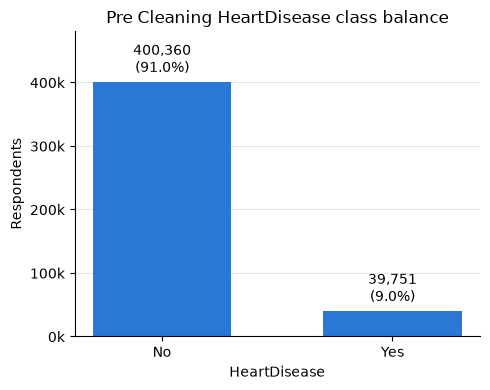

In [13]:
import matplotlib.pyplot as plt

labelled = balance.loc[["No", "Yes"]]

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(labelled.index, labelled["count"], color="#2a78d6", width=0.6)
ax.bar_label(
    bars,
    labels=[f"{c:,}\n({p:.1f}%)" for c, p in zip(labelled["count"], labelled["% of labelled rows"])],
    padding=4,
)
ax.set_title("Pre Cleaning HeartDisease class balance")
ax.set_xlabel("HeartDisease")
ax.set_ylabel("Respondents")
ax.yaxis.set_major_formatter(lambda y, _: f"{y / 1000:.0f}k")
ax.set_ylim(0, labelled["count"].max() * 1.2)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("figures/eda/target_balance.png", dpi=200)
plt.show()

### Findings

- 39,751 Yes vs 400,360 No: **9.0% positive** among labelled rows, matching the proposal. A model that always predicts No would be 91% accurate, so accuracy is not a useful metric here.
- 5,021 rows (1.1%) have an unknown target and can't be used for training.
- The two questions overlap: 11,908 respondents said Yes to both, so the combined target counts them once.
- `HadHeartAttack` and `HadAngina` must be dropped as features once the target is built, or the model sees the answer.

## 3. Missing values

### Missing values per column

In [14]:
features = df.columns.drop("HeartDisease")

missing = pd.DataFrame({
    "n_missing": df[features].isna().sum(),
    "% missing": (df[features].isna().mean() * 100).round(2),
}).sort_values("% missing", ascending=False)
missing

,n_missing,% missing
TetanusLast10Tdap,82516,18.54
PneumoVaxEver,77040,17.31
HIVTesting,66127,14.86
ChestScan,56046,12.59
CovidPos,50764,11.40
HighRiskLastYear,50623,11.37
BMI,48806,10.96
FluVaxLast12,47121,10.59
AlcoholDrinkers,46574,10.46
WeightInKilograms,42078,9.45


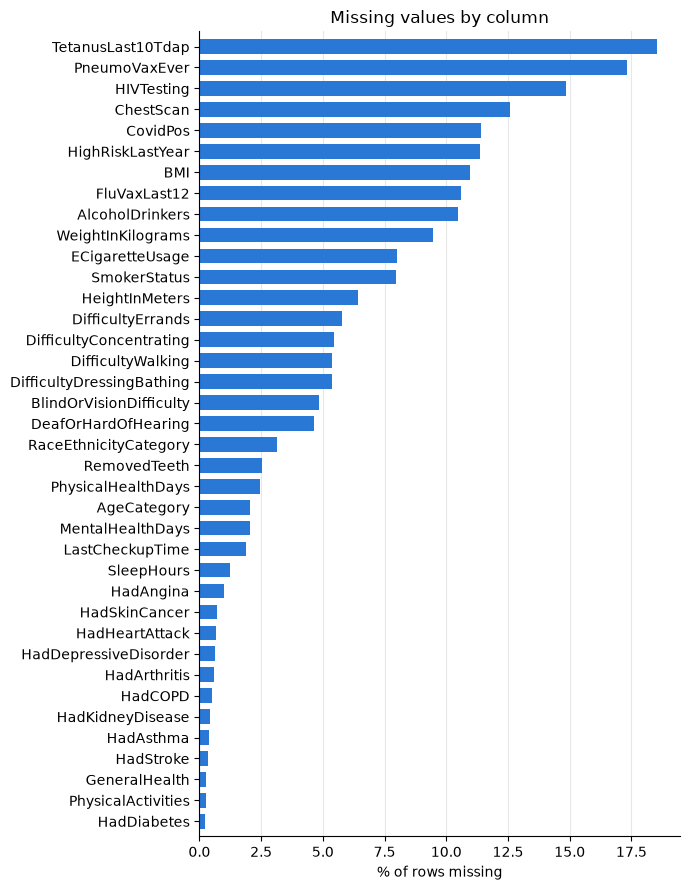

In [15]:
plot_data = missing[missing["n_missing"] > 0].sort_values("% missing")

fig, ax = plt.subplots(figsize=(7, 9))
ax.barh(plot_data.index, plot_data["% missing"], color="#2a78d6", height=0.7)
ax.set_title("Missing values by column")
ax.set_xlabel("% of rows missing")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.margins(y=0.01)

fig.tight_layout()
fig.savefig("figures/eda/missing_by_column.png", dpi=200)
plt.show()

### Missing values per row

How many questions each respondent left blank.

Rows with no missing values: 55.3%


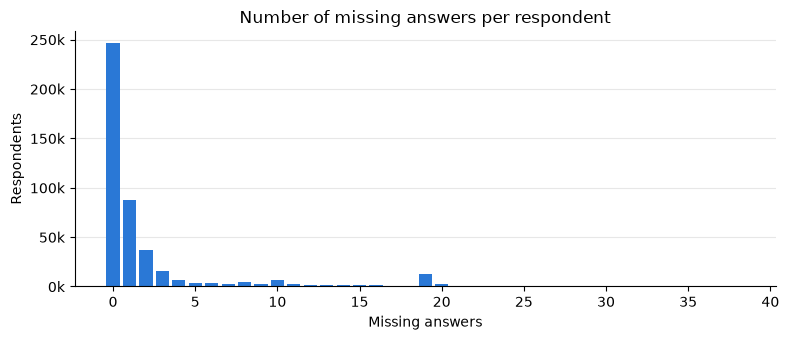

In [16]:
missing_per_row = df[features].isna().sum(axis=1)
print(f"Rows with no missing values: {(missing_per_row == 0).mean() * 100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(missing_per_row.value_counts().sort_index().index,
       missing_per_row.value_counts().sort_index().values,
       color="#2a78d6", width=0.8)
ax.set_title("Number of missing answers per respondent")
ax.set_xlabel("Missing answers")
ax.set_ylabel("Respondents")
ax.yaxis.set_major_formatter(lambda y, _: f"{y / 1000:.0f}k")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("figures/eda/missing_per_row.png", dpi=200)
plt.show()

In [17]:
# The spike at 19: which columns are blank for those respondents?
spike = df.loc[missing_per_row == 19, features].isna().mean() * 100
spike[spike > 50].sort_values(ascending=False).round(0)

TetanusLast10Tdap            100.0
ChestScan                    100.0
AlcoholDrinkers              100.0
HIVTesting                   100.0
FluVaxLast12                 100.0
CovidPos                     100.0
PneumoVaxEver                100.0
HighRiskLastYear             100.0
SmokerStatus                 100.0
ECigaretteUsage              100.0
DifficultyErrands            100.0
BMI                          100.0
DifficultyDressingBathing    100.0
DifficultyWalking            100.0
DifficultyConcentrating      100.0
BlindOrVisionDifficulty      100.0
HeightInMeters               100.0
DeafOrHardOfHearing          100.0
WeightInKilograms             99.0
dtype: float64

### Which columns are missing together

Correlation between the missing-value indicators of columns with more than 1% missing. A value near 1 means the two columns are almost always blank in the same rows.

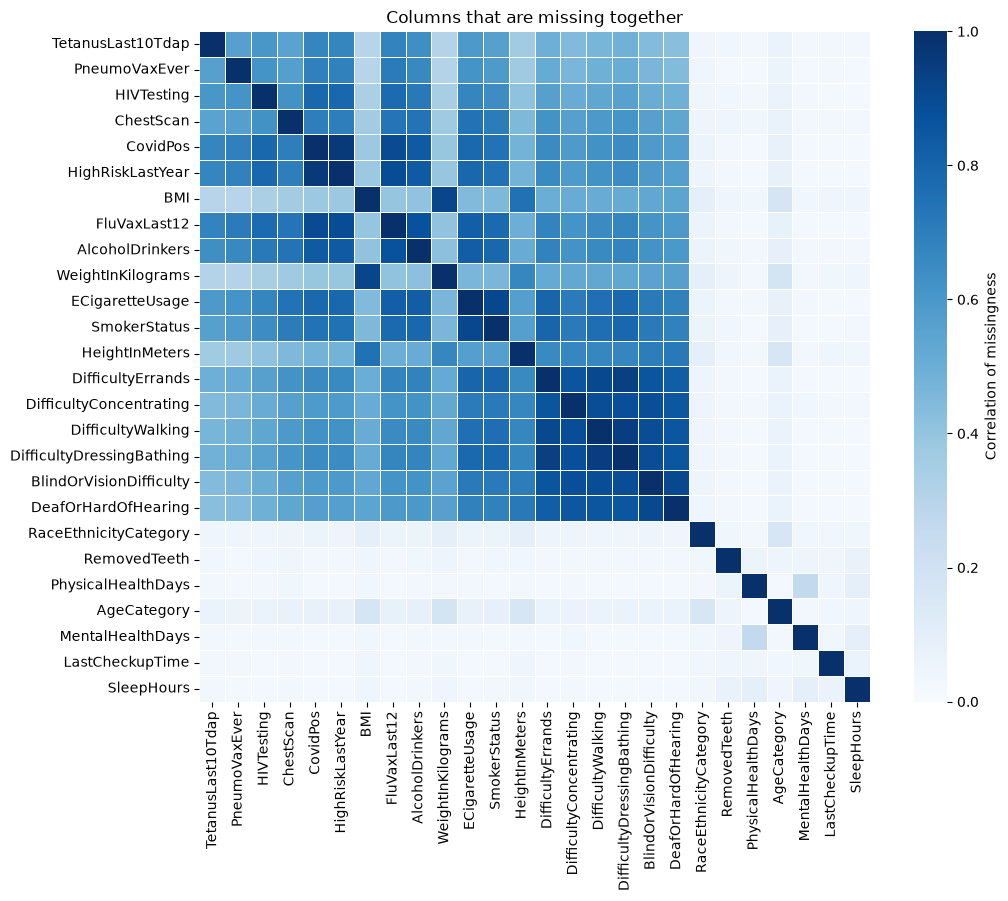

In [18]:
import seaborn as sns

often_missing = missing.index[missing["% missing"] > 1]
nullity_corr = df[often_missing].isna().astype(int).corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(nullity_corr, cmap="Blues", vmin=0, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"label": "Correlation of missingness"}, ax=ax)
ax.set_title("Columns that are missing together")

fig.tight_layout()
fig.savefig("figures/eda/missing_correlation.png", dpi=200)
plt.show()

In [19]:
# Height, weight and BMI: BMI is missing whenever height or weight is,
# but some rows have both height and weight and still no BMI
df[["HeightInMeters", "WeightInKilograms", "BMI"]].isna().value_counts()

HeightInMeters  WeightInKilograms  BMI  
False           False              False    396326
True            True               True      24162
False           True               True      17916
True            False              True       4490
False           False              True       2238
Name: count, dtype: int64

### Is missingness related to heart disease?

Heart disease rate among respondents who left each column blank vs those who answered it (labelled rows only, columns with at least 1,000 blanks). The target source columns are excluded.

In [20]:
labelled_rows = df[df["HeartDisease"].notna()]
is_yes = labelled_rows["HeartDisease"] == "Yes"

rate_by_missing = pd.DataFrame({
    "n_missing": labelled_rows[features].isna().sum(),
    "% HD when missing": [is_yes[labelled_rows[c].isna()].mean() * 100 for c in features],
    "% HD when answered": [is_yes[labelled_rows[c].notna()].mean() * 100 for c in features],
}, index=features).drop(["HadHeartAttack", "HadAngina"])

rate_by_missing[rate_by_missing["n_missing"] >= 1000] \
    .sort_values("% HD when missing", ascending=False).round(1)

,n_missing,% HD when missing,% HD when answered
HadStroke,1025,29.3,9.0
HadKidneyDisease,1521,22.4,9.0
HadCOPD,1747,18.6,9.0
HadSkinCancer,2671,17.7,9.0
GeneralHealth,1063,15.1,9.0
SleepHours,5113,14.7,9.0
RemovedTeeth,10861,14.3,8.9
PhysicalHealthDays,10443,14.3,8.9
MentalHealthDays,8686,12.2,9.0
HadAsthma,1392,12.2,9.0


### Findings

- **45% of respondents have at least one blank**, but most columns are mostly complete: only 5% of all cells are missing, and the worst column (`TetanusLast10Tdap`) is 18.5% missing. Dropping every incomplete row would throw away almost half the data, so imputation is needed.
- **Later survey questions are missing most.** Vaccination, HIV testing, chest scan, COVID and alcohol questions have 10–19% missing, while the core health and medical history questions have under 1%.
- **Survey break-off.** About 13,000 respondents are missing exactly 19 answers: everything from the disability questions onward. They most likely ended the phone call partway through. This explains why groups of columns (disability questions, smoking/e-cigarettes, vaccinations/COVID/high risk) are missing together.
- **Height, weight and BMI.** BMI is missing whenever height or weight is, and 2,238 rows have both height and weight but no BMI. BMI can be recalculated for those rows.
- **Missingness carries signal.** For medical history and general health questions, respondents who left the answer blank have a much higher heart disease rate (e.g. 29% when `HadStroke` is blank vs 9% overall). Keeping an "Unknown" category or a missing indicator may be better than filling with the most common answer.

## 4. Numeric features

### Summary statistics

In [21]:
numeric_stats = df[numeric_cols].describe().T
numeric_stats["skew"] = df[numeric_cols].skew()
numeric_stats["% zero"] = (df[numeric_cols] == 0).mean() * 100
numeric_stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,% zero
PhysicalHealthDays,434205.0,4.35,8.69,0.00,0.00,0.00,3.00,30.00,2.18,60.17
MentalHealthDays,436065.0,4.38,8.39,0.00,0.00,0.00,5.00,30.00,2.12,59.58
SleepHours,439679.0,7.02,1.50,1.00,6.00,7.00,8.00,24.00,0.76,0.00
HeightInMeters,416480.0,1.70,0.11,0.91,1.63,1.70,1.78,2.41,0.03,0.00
WeightInKilograms,403054.0,83.07,21.45,22.68,68.04,80.74,95.25,292.57,1.08,0.00
BMI,396326.0,28.53,6.55,12.02,24.13,27.44,31.75,99.64,1.39,0.00


### Distributions

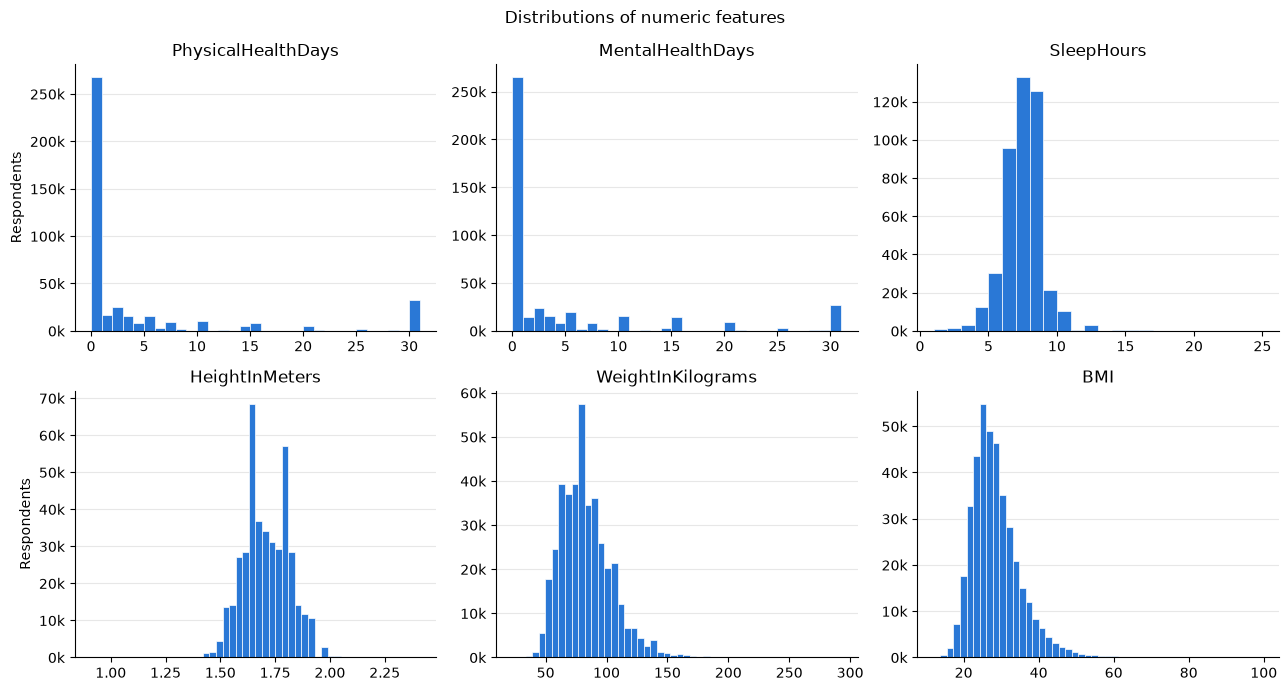

In [22]:
bins = {
    "PhysicalHealthDays": range(0, 32),
    "MentalHealthDays": range(0, 32),
    "SleepHours": range(1, 26),
    "HeightInMeters": 50,
    "WeightInKilograms": 50,
    "BMI": 50,
}

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, numeric_cols):
    ax.hist(df[col].dropna(), bins=bins[col], color="#2a78d6", edgecolor="white", linewidth=0.5)
    ax.set_title(col)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y / 1000:.0f}k")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
for ax in axes[:, 0]:
    ax.set_ylabel("Respondents")
fig.suptitle("Distributions of numeric features")

fig.tight_layout()
fig.savefig("figures/eda/numeric_distributions.png", dpi=200)
plt.show()

### Outliers

Values outside the plausible ranges defined in the data quality baseline (section 1).

In [23]:
outliers = pd.DataFrame({
    "range": [f"{low}–{high}" for low, high in plausible_ranges.values()],
    "below": [(df[col] < low).sum() for col, (low, high) in plausible_ranges.items()],
    "above": [(df[col] > high).sum() for col, (low, high) in plausible_ranges.items()],
    "min": [df[col].min() for col in plausible_ranges],
    "max": [df[col].max() for col in plausible_ranges],
}, index=list(plausible_ranges))
outliers

,range,below,above,min,max
PhysicalHealthDays,0–30,0,0,0.00,30.00
MentalHealthDays,0–30,0,0,0.00,30.00
SleepHours,3–16,2703,447,1.00,24.00
HeightInMeters,1.2–2.2,133,37,0.91,2.41
WeightInKilograms,30–250,72,34,22.68,292.57
BMI,13–70,74,224,12.02,99.64


### Sleep hours

Counts at the extremes. Sleeping 1–2 hours or 20+ hours a night on average is very unlikely, especially for respondents who also report excellent health.

In [24]:
extreme_sleep = df["SleepHours"].isin(range(1, 3)) | (df["SleepHours"] >= 16)
pd.crosstab(df.loc[extreme_sleep, "SleepHours"], df.loc[extreme_sleep, "GeneralHealth"], margins=True)

GeneralHealth,Excellent,Fair,Good,Poor,Very good,All
SleepHours,,,,,,
1.0,184,152,377,91,345,1149
2.0,207,327,416,324,270,1544
16.0,30,74,83,81,60,328
17.0,4,8,4,8,3,27
18.0,15,42,37,55,18,167
19.0,4,3,5,2,2,16
20.0,10,38,32,37,25,142
21.0,1,1,1,0,1,4
22.0,4,3,3,7,1,18


### Height, weight and BMI

Each point is a respondent (random sample of 50,000). Orange points have a height, weight or BMI outside the plausible ranges.

In [26]:
# What drives extreme BMI: an unusual height, an unusual weight, or neither?
height_odd = ~df["HeightInMeters"].between(1.4, 2.1)
weight_odd = ~df["WeightInKilograms"].between(40, 180)

bmi_causes = pd.DataFrame({
    bmi_label: {
        "rows": mask.sum(),
        "height outside 1.4–2.1 m": (mask & height_odd).sum(),
        "weight outside 40–180 kg": (mask & weight_odd).sum(),
        "both height and weight normal": (mask & ~height_odd & ~weight_odd).sum(),
    }
    for bmi_label, mask in {"BMI < 15": df["BMI"] < 15, "BMI > 60": df["BMI"] > 60}.items()
})
bmi_causes

,BMI < 15,BMI > 60
rows,433,739
height outside 1.4–2.1 m,8,80
weight outside 40–180 kg,166,368
both height and weight normal,259,292


In [27]:
# Shortest respondents: very short heights paired with normal or heavy weights look like entry errors
df.loc[df["HeightInMeters"] < 1.2, ["Sex", "AgeCategory", "HeightInMeters", "WeightInKilograms", "BMI"]] \
    .sort_values("HeightInMeters")

,Sex,AgeCategory,HeightInMeters,WeightInKilograms,BMI
9097,Male,Age 80 or older,0.91,95.25,NaN
106662,Female,Age 18 to 24,0.91,40.82,48.82
121126,Female,Age 50 to 54,0.91,68.04,81.37
164227,Male,Age 45 to 49,0.91,97.07,NaN
186028,Female,Age 60 to 64,0.91,81.65,97.65
...,...,...,...,...,...
265251,Female,Age 55 to 59,1.19,NaN,NaN
61648,Female,Age 65 to 69,1.19,58.97,41.38
60285,Male,Age 55 to 59,1.19,62.60,43.92
274213,Male,Age 18 to 24,1.19,63.50,44.56


### BMI blank despite height and weight

2,238 rows have height and weight but no BMI (section 3). Calculating it shows whether it was removed because it would have been impossible.

In [28]:
bmi_blank = df["BMI"].isna() & df["HeightInMeters"].notna() & df["WeightInKilograms"].notna()
calculated_bmi = df.loc[bmi_blank, "WeightInKilograms"] / df.loc[bmi_blank, "HeightInMeters"] ** 2

print(f"Rows with height and weight but no BMI: {bmi_blank.sum():,}")
print(f"Calculated BMI < 12 or > 100: {((calculated_bmi < 12) | (calculated_bmi > 100)).sum():,}")
calculated_bmi.describe().round(1)

Rows with height and weight but no BMI: 2,238
Calculated BMI < 12 or > 100: 159


count    2238.0
mean       29.1
std        13.1
min         6.8
25%        23.5
50%        27.6
75%        32.4
max       235.5
dtype: float64

### Findings

- **Health days are mostly zero.** About 60% of respondents report 0 bad physical or mental health days, with a second spike at 30 ("every day"). The distributions are heavily right-skewed (skew ≈ 2.1). All values are within the valid 0–30 range.
- **Sleep has the most implausible values.** About 2,700 respondents report under 3 hours a night (1,154 say 1 hour) and about 450 report over 16 hours, including 52 who say 24. 391 of the 1–2 hour sleepers also report excellent health, which suggests misunderstood questions or entry errors rather than real values.
- **Some heights are clearly wrong.** 274 respondents are under 1.3 m (down to 0.91 m) and 110 are over 2.1 m. Very short heights paired with normal or heavy weights (e.g. 0.91 m and 195 kg) are almost certainly entry errors.
- **Extreme BMI comes from both real and wrong values.** Of the 739 rows with BMI over 60, about half have a weight over 180 kg (plausibly real), while 80 come from heights under 1.4 m. BMI under 15 mostly comes from tall, very light respondents (median 1.75 m and 41 kg): each value alone is possible, but the combination is not. Because BMI is calculated from height and weight, an error in either one creates an extreme BMI.
- **BMI was blanked for some impossible values.** Of the 2,238 rows with height and weight but no BMI, 159 would have a BMI under 12 or over 100. The rest look normal, so BMI can be recalculated for them.
- **Some answers contradict each other.** 744 respondents report 30 bad physical health days but excellent general health, and 1,103 report poor health but 0 bad days. These are possible (e.g. a chronic condition someone has adapted to) but show the data is noisy self-reports.
- **Answers are rounded.** About 99% of weights are a whole number of pounds, heights cluster on whole inches, and health days spike at 5, 10, 15 and 20. This is normal for survey data but limits precision.

## 5. Categorical features

### Overview

For each categorical column: number of categories, the most and least common answer, and how dominant the most common answer is (among those who answered).

In [29]:
def describe_categorical(col):
    shares = df[col].value_counts(normalize=True) * 100
    return {
        "n_categories": len(shares),
        "most common": shares.index[0],
        "% most common": round(shares.iloc[0], 1),
        "least common": shares.index[-1],
        "% least common": round(shares.iloc[-1], 2),
        "% missing": round(df[col].isna().mean() * 100, 1),
    }

categorical_overview = pd.DataFrame({col: describe_categorical(col) for col in categorical_cols}).T
categorical_overview.sort_values("% most common", ascending=False)

,n_categories,most common,% most common,least common,% least common,% missing
DifficultyDressingBathing,2,No,96.0,Yes,3.99,5.4
HadStroke,2,No,95.7,Yes,4.34,0.3
HighRiskLastYear,2,No,95.6,Yes,4.36,11.4
HadKidneyDisease,2,No,95.4,Yes,4.58,0.4
BlindOrVisionDifficulty,2,No,94.4,Yes,5.59,4.8
HadHeartAttack,2,No,94.3,Yes,5.68,0.7
HadAngina,2,No,94.0,Yes,6.02,1.0
DifficultyErrands,2,No,92.3,Yes,7.74,5.8
HadSkinCancer,2,No,92.0,Yes,8.03,0.7
HadCOPD,2,No,91.9,Yes,8.05,0.5


### Yes/No questions

Share of respondents answering Yes (among those who answered). `Sex` is the only other two-category column (53% female, 47% male).

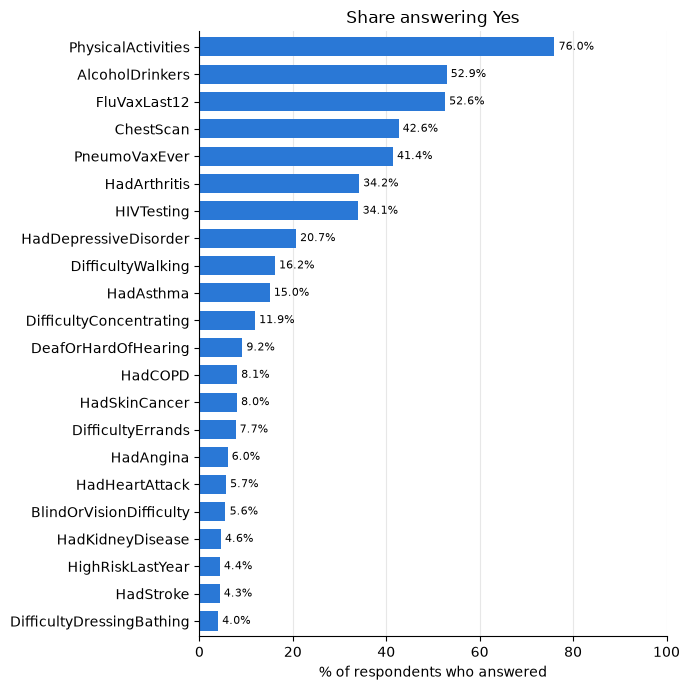

In [30]:
binary_cols = [col for col in categorical_cols if set(df[col].dropna().unique()) == {"Yes", "No"}]
yes_rate = ((df[binary_cols] == "Yes").sum() / df[binary_cols].notna().sum() * 100).sort_values()

fig, ax = plt.subplots(figsize=(7, 7))
bars = ax.barh(yes_rate.index, yes_rate.values, color="#2a78d6", height=0.7)
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
ax.set_title("Share answering Yes")
ax.set_xlabel("% of respondents who answered")
ax.set_xlim(0, 100)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.margins(y=0.01)

fig.tight_layout()
fig.savefig("figures/eda/binary_yes_rate.png", dpi=200)
plt.show()

### Multi-category questions

Ordered columns are shown in their natural order; the others are sorted by size.

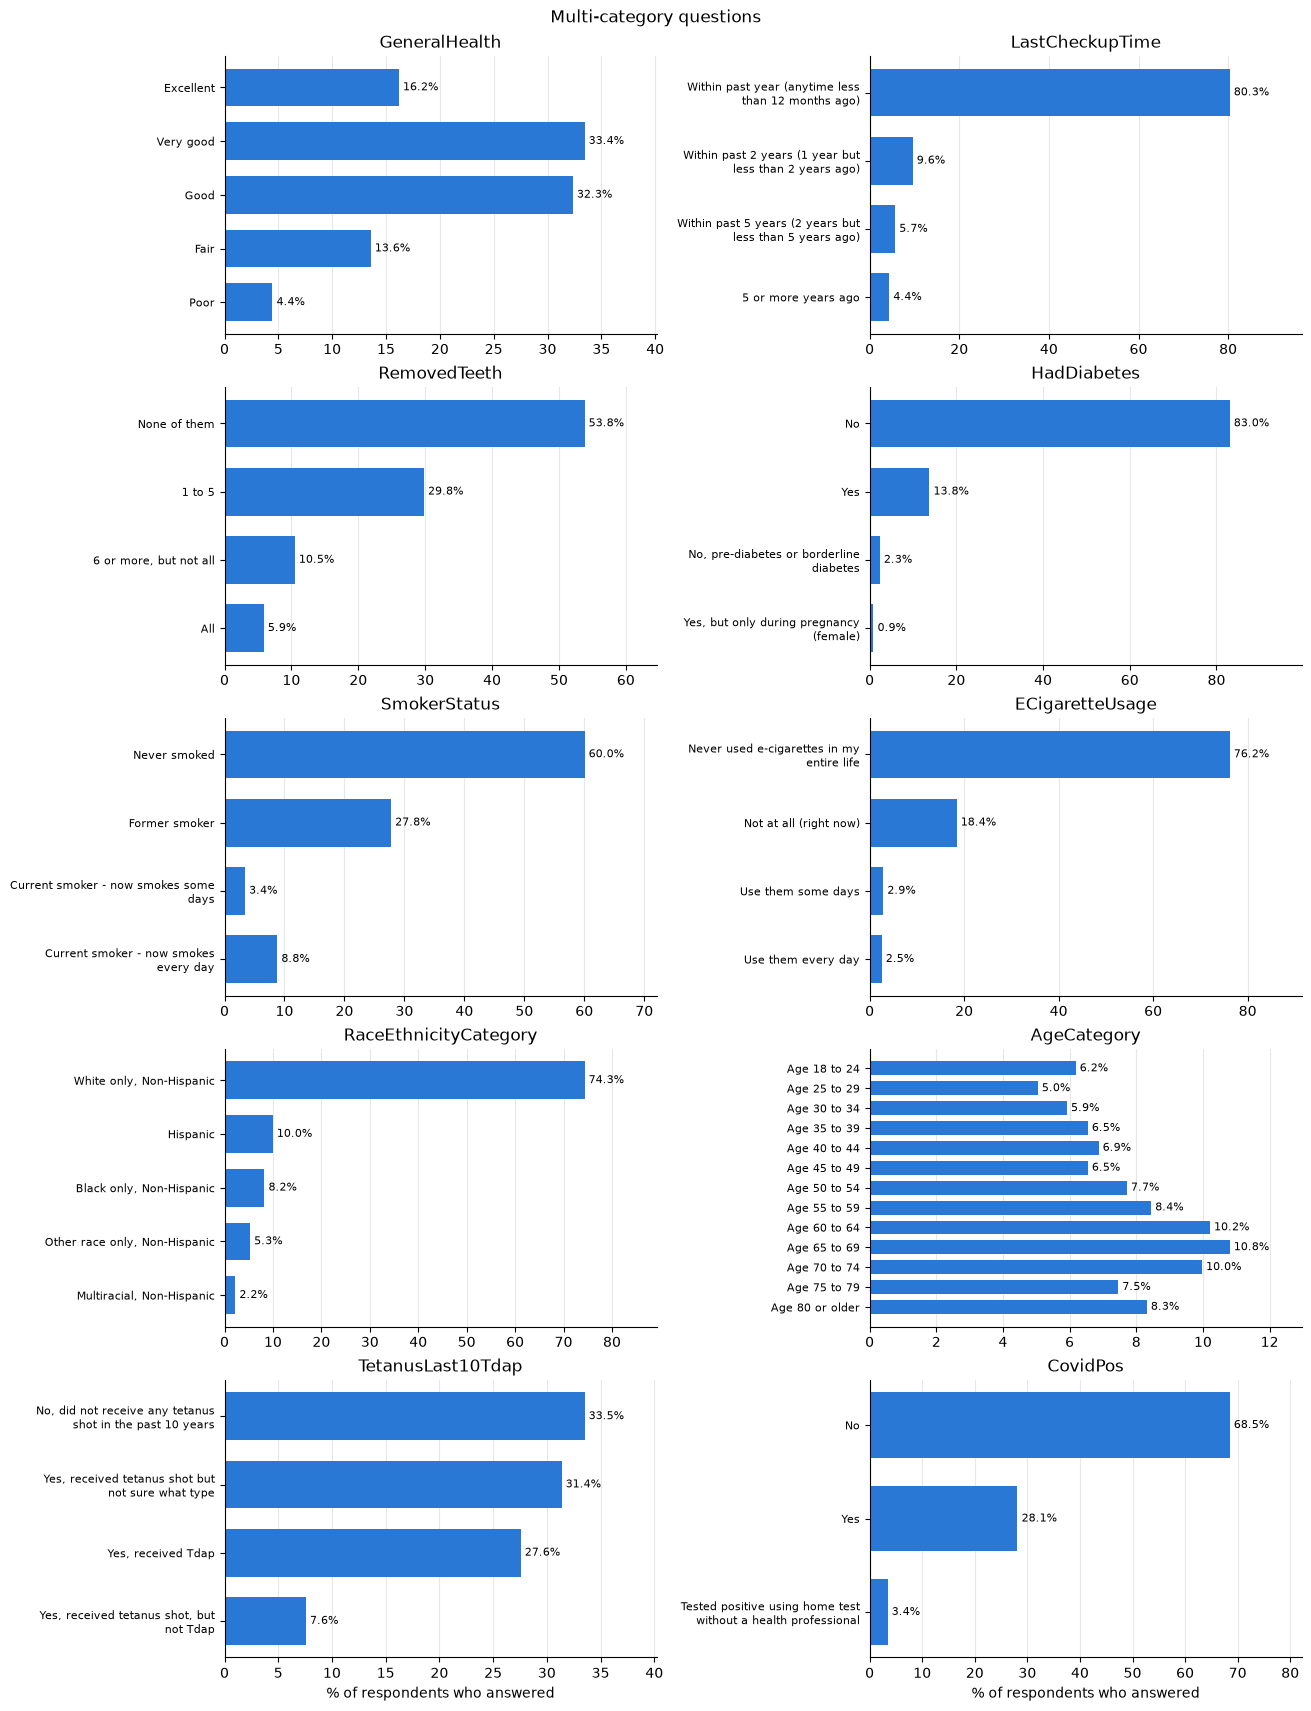

In [31]:
import textwrap

category_order = {
    "AgeCategory": sorted(df["AgeCategory"].dropna().unique()),
    "GeneralHealth": ["Excellent", "Very good", "Good", "Fair", "Poor"],
    "LastCheckupTime": [
        "Within past year (anytime less than 12 months ago)",
        "Within past 2 years (1 year but less than 2 years ago)",
        "Within past 5 years (2 years but less than 5 years ago)",
        "5 or more years ago",
    ],
    "RemovedTeeth": ["None of them", "1 to 5", "6 or more, but not all", "All"],
    "SmokerStatus": [
        "Never smoked", "Former smoker",
        "Current smoker - now smokes some days", "Current smoker - now smokes every day",
    ],
    "ECigaretteUsage": [
        "Never used e-cigarettes in my entire life", "Not at all (right now)",
        "Use them some days", "Use them every day",
    ],
}
multi_cols = [col for col in categorical_cols if df[col].nunique() > 2 and col != "State"]

fig, axes = plt.subplots(5, 2, figsize=(13, 17), layout="constrained")
for ax, col in zip(axes.flat, multi_cols):
    shares = df[col].value_counts(normalize=True) * 100
    order = category_order.get(col, list(shares.sort_values().index))
    shares = shares.reindex(order)
    labels = [textwrap.fill(label, 32) for label in shares.index]
    bars = ax.barh(labels, shares.values, color="#2a78d6", height=0.7)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
    if col in category_order:
        ax.invert_yaxis()
    ax.set_title(col)
    ax.set_xlim(0, shares.max() * 1.2)
    ax.tick_params(axis="y", labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
for ax in axes[-1]:
    ax.set_xlabel("% of respondents who answered")
fig.suptitle("Multi-category questions")

fig.savefig("figures/eda/categorical_distributions.png", dpi=200)
plt.show()

### State

54 levels: the 50 states plus the District of Columbia, Guam, Puerto Rico and the US Virgin Islands.

In [32]:
state_counts = df["State"].value_counts()
print(f"Respondents per state: median {state_counts.median():,.0f}, "
      f"min {state_counts.min():,} ({state_counts.idxmin()}), max {state_counts.max():,} ({state_counts.idxmax()})")
pd.concat([state_counts.head(5), state_counts.tail(5)]).to_frame("respondents")

Respondents per state: median 7,431, min 1,531 (Virgin Islands), max 26,152 (Washington)


,respondents
State,
Washington,26152
New York,17800
Minnesota,16821
Ohio,16487
Maryland,16418
Delaware,3987
District of Columbia,3237
Nevada,3188
Guam,2266


### Column types for encoding

In [33]:
ordinal_cols = list(category_order) + ["HadDiabetes"]
nominal_cols = ["State", "RaceEthnicityCategory", "TetanusLast10Tdap", "CovidPos"]

column_types = pd.DataFrame({
    "type": ["Binary (Yes/No)", "Binary (Female/Male)", "Ordered", "Unordered"],
    "count": [len(binary_cols), 1, len(ordinal_cols), len(nominal_cols)],
    "columns": [", ".join(binary_cols), "Sex", ", ".join(ordinal_cols), ", ".join(nominal_cols)],
}).set_index("type")
column_types

,count,columns
type,,
Binary (Yes/No),22,"PhysicalActivities, HadHeartAttack, HadAngina,..."
Binary (Female/Male),1,Sex
Ordered,7,"AgeCategory, GeneralHealth, LastCheckupTime, R..."
Unordered,4,"State, RaceEthnicityCategory, TetanusLast10Tda..."


### Findings

- **The categorical data is clean.** Every column uses a small, consistent set of answers with no spelling variants or stray values, so no text cleaning is needed.
- **The sample skews older.** The largest age groups are 60–74, and 18–24 makes up only 6% of respondents. Heart disease is far more common with age, so this affects the positive rate.
- **Many Yes/No questions are rare events.** Stroke, kidney disease, difficulty dressing and high-risk behaviour are each answered Yes by under 5% of respondents. These columns carry little information individually.
- **Some columns mix several ideas into one answer.**
  - `HadDiabetes` includes "pre-diabetes" and "only during pregnancy", which sit between No and Yes.
  - `TetanusLast10Tdap` has three different Yes answers that differ only by vaccine type; it could be reduced to Yes/No.
  - `CovidPos` has a third answer, "positive on a home test", which is effectively Yes.
- **`State` sizes vary a lot** (1,531 respondents in the Virgin Islands vs 26,152 in Washington) and don't follow population: Washington has more respondents than New York, and Illinois has about 4,000. This reflects how each state ran the survey, so `State` is unlikely to be a useful predictor, and one-hot encoding it would add 54 columns.
- **Encoding.** 22 columns are Yes/No, 1 is Female/Male, 7 have a natural order (age, general health, last checkup, teeth removed, smoking, e-cigarettes, diabetes) and should be encoded as ordered numbers, and 4 have no order and need one-hot encoding.

## 6. Relationships

### Numeric features: correlation

Pearson correlation between the numeric features.

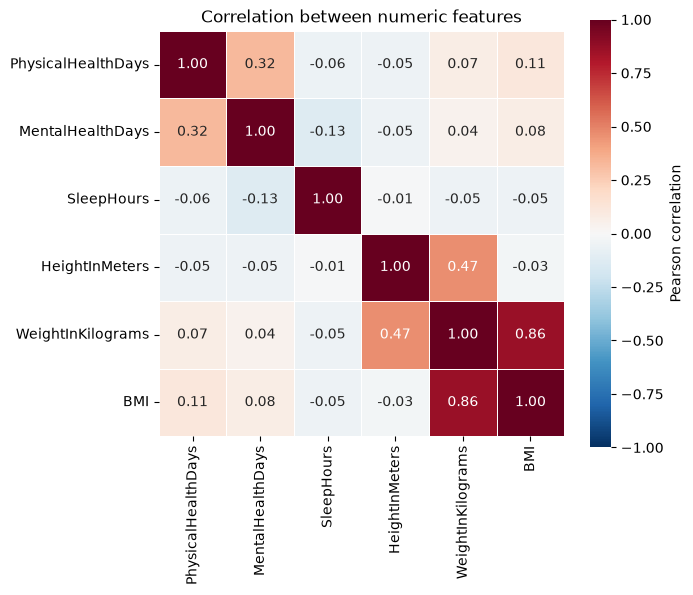

In [34]:
numeric_corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(numeric_corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation between numeric features")

fig.tight_layout()
fig.savefig("figures/eda/numeric_correlation.png", dpi=200)
plt.show()

### All features: association

Pearson correlation only works for numbers, so for categorical features we use **Cramér's V**, which measures how strongly two categorical variables are associated on a 0 (none) to 1 (perfect) scale. Numeric features are split into 10 equal-sized bins so every feature can be compared on the same scale. Missing values are left out pair by pair.

In [35]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if min(table.shape) < 2:
        return float("nan")
    chi2 = chi2_contingency(table, correction=False)[0]
    return (chi2 / (table.values.sum() * (min(table.shape) - 1))) ** 0.5

# Numeric features binned into deciles so they can be compared with categorical ones
binned = df[features].copy()
for col in numeric_cols:
    binned[col] = pd.qcut(df[col], 10, duplicates="drop")

feature_cols = [col for col in features if col not in ("HadHeartAttack", "HadAngina")]

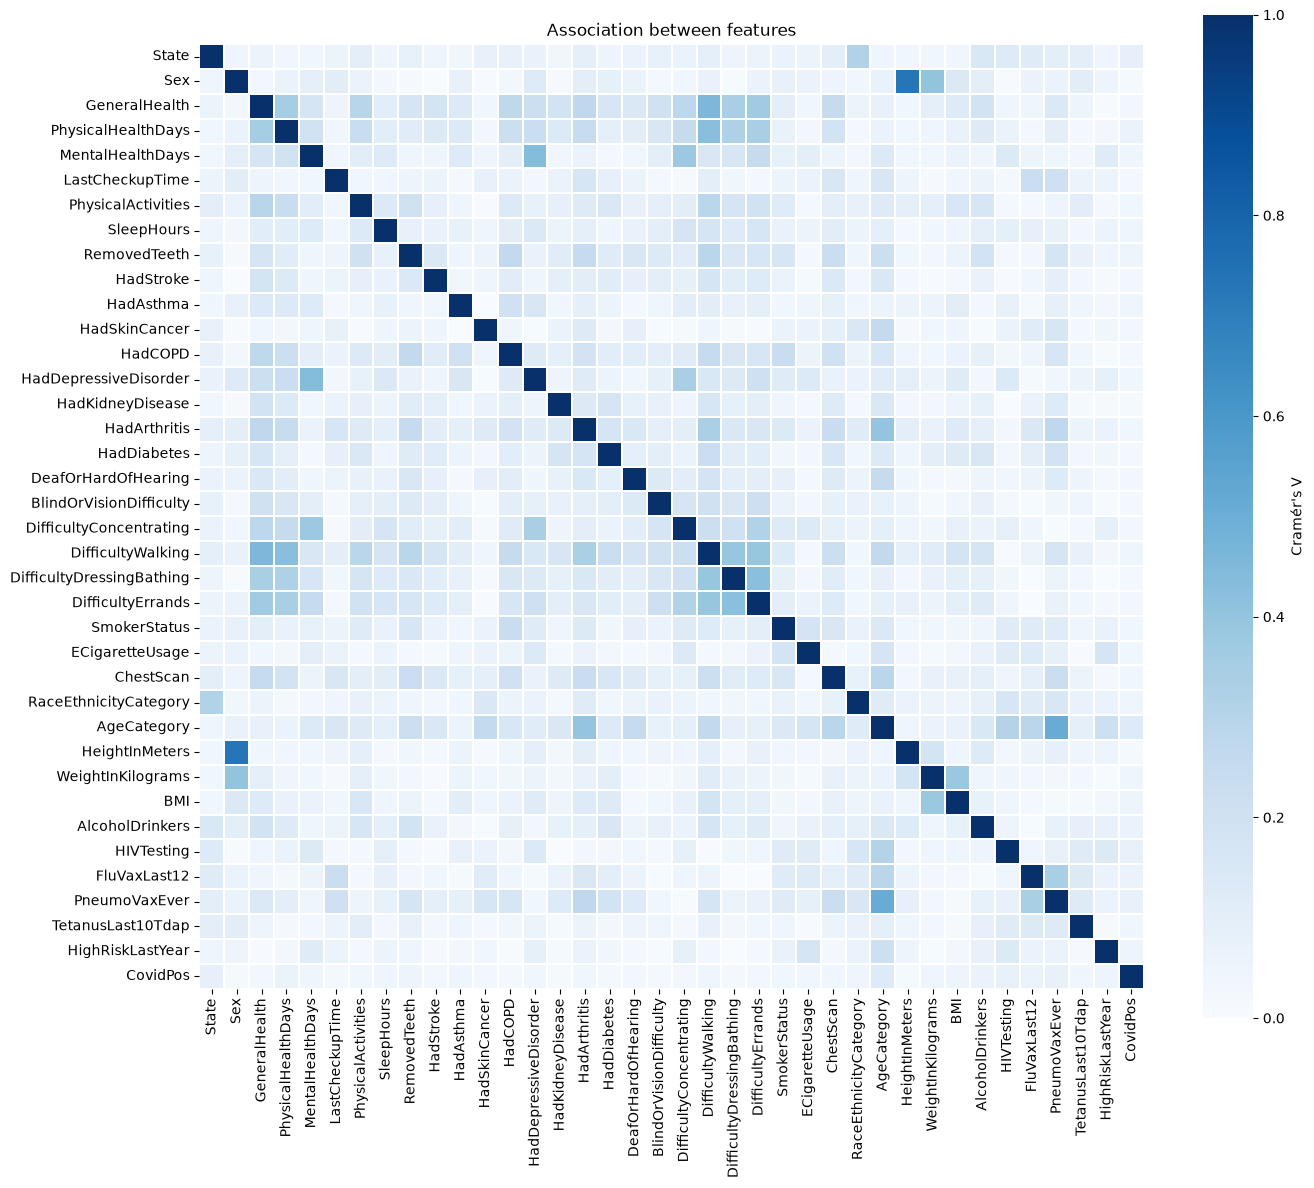

In [36]:
association = pd.DataFrame(1.0, index=feature_cols, columns=feature_cols)
for i, a in enumerate(feature_cols):
    for b in feature_cols[i + 1:]:
        association.loc[a, b] = association.loc[b, a] = cramers_v(binned[a], binned[b])

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(association, cmap="Blues", vmin=0, vmax=1, square=True, linewidths=0.3,
            cbar_kws={"label": "Cramér's V"}, ax=ax)
ax.set_title("Association between features")

fig.tight_layout()
fig.savefig("figures/eda/feature_association.png", dpi=200)
plt.show()

In [37]:
# Most strongly associated feature pairs (possible redundancy)
pairs = association.where(pd.DataFrame(
    [[i < j for j in range(len(feature_cols))] for i in range(len(feature_cols))],
    index=feature_cols, columns=feature_cols,
)).stack().sort_values(ascending=False)
pairs.head(15).round(2).to_frame("Cramér's V")

Cramér's V
Sex                       HeightInMeters                   0.73
AgeCategory               PneumoVaxEver                    0.51
GeneralHealth             DifficultyWalking                0.46
MentalHealthDays          HadDepressiveDisorder            0.44
PhysicalHealthDays        DifficultyWalking                0.43
DifficultyDressingBathing DifficultyErrands                0.42
Sex                       WeightInKilograms                0.40
HadArthritis              AgeCategory                      0.40
DifficultyWalking         DifficultyDressingBathing        0.39
                          DifficultyErrands                0.39
WeightInKilograms         BMI                              0.39
MentalHealthDays          DifficultyConcentrating          0.38
GeneralHealth             DifficultyErrands                0.37
                          PhysicalHealthDays               0.35
FluVaxLast12              PneumoVaxEver                    0.34

### Heart disease rate by category

Share of respondents with heart disease in each category of the key features (labelled rows only). The dashed line is the overall rate of 9.0%.

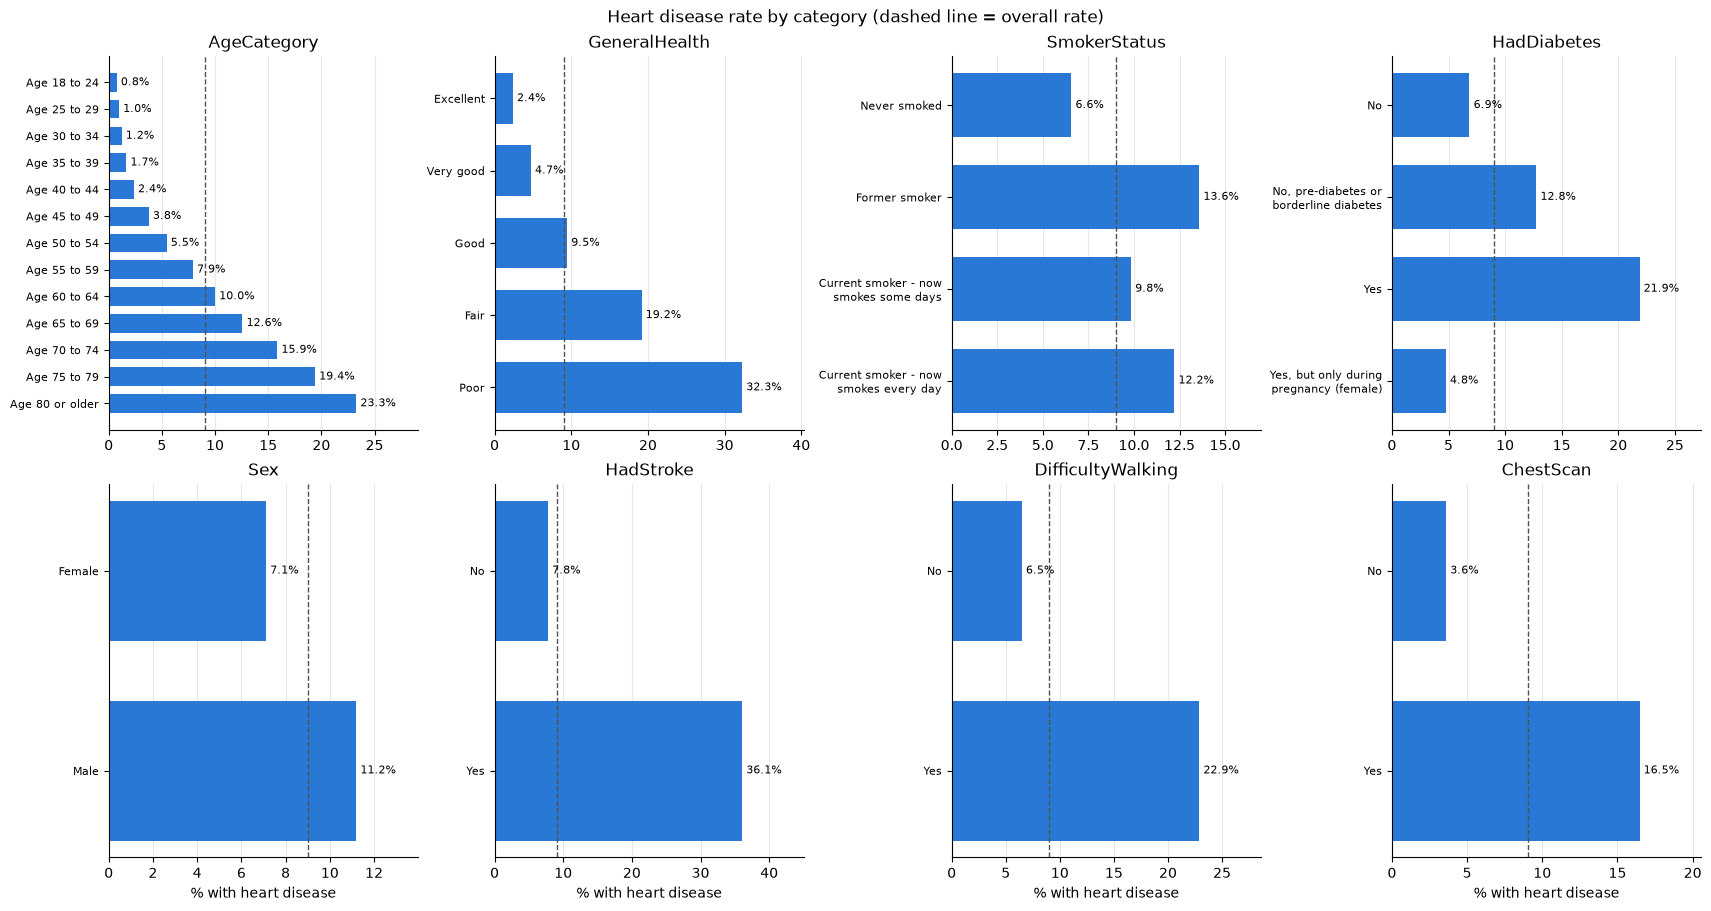

In [38]:
overall_rate = is_yes.mean() * 100
key_features = ["AgeCategory", "GeneralHealth", "SmokerStatus", "HadDiabetes",
                "Sex", "HadStroke", "DifficultyWalking", "ChestScan"]

fig, axes = plt.subplots(2, 4, figsize=(17, 9), layout="constrained")
for ax, col in zip(axes.flat, key_features):
    rate = labelled_rows.groupby(col)["HeartDisease"].apply(lambda s: (s == "Yes").mean() * 100)
    rate = rate.reindex(category_order.get(col, rate.index))
    labels = [textwrap.fill(label, 22) for label in rate.index]
    bars = ax.barh(labels, rate.values, color="#2a78d6", height=0.7)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
    ax.axvline(overall_rate, color="#52514e", linestyle="--", linewidth=1)
    ax.invert_yaxis()
    ax.set_title(col)
    ax.set_xlim(0, rate.max() * 1.25)
    ax.tick_params(axis="y", labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
for ax in axes[-1]:
    ax.set_xlabel("% with heart disease")
fig.suptitle("Heart disease rate by category (dashed line = overall rate)")

fig.savefig("figures/eda/heart_disease_rate_by_category.png", dpi=200)
plt.show()

### Ranking features by association with HeartDisease

Cramér's V between each feature and `HeartDisease`. `HadHeartAttack` and `HadAngina` are excluded because the target is built from them.

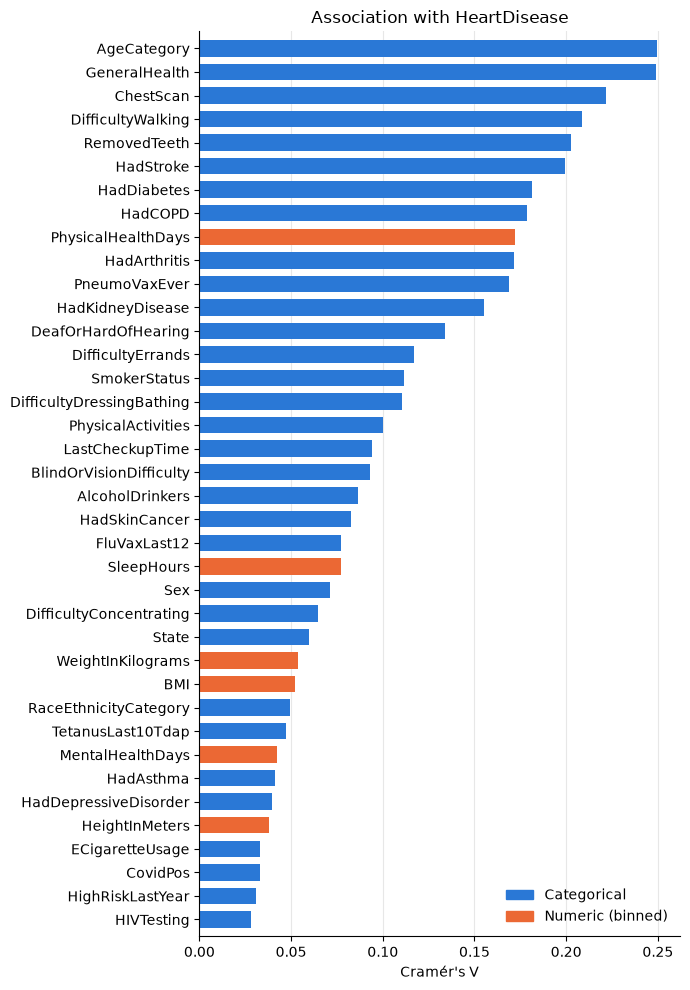

In [39]:
target_association = pd.Series(
    {col: cramers_v(binned.loc[labelled_rows.index, col], labelled_rows["HeartDisease"]) for col in feature_cols}
).sort_values()

colors = ["#eb6834" if col in numeric_cols else "#2a78d6" for col in target_association.index]

fig, ax = plt.subplots(figsize=(7, 10))
ax.barh(target_association.index, target_association.values, color=colors, height=0.7)
ax.set_title("Association with HeartDisease")
ax.set_xlabel("Cramér's V")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.margins(y=0.01)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#2a78d6"), plt.Rectangle((0, 0), 1, 1, color="#eb6834")],
          labels=["Categorical", "Numeric (binned)"], loc="lower right", frameon=False)

fig.tight_layout()
fig.savefig("figures/eda/feature_ranking.png", dpi=200)
plt.show()

### ChestScan: possible leakage

`ChestScan` asks whether the respondent has ever had a CT or CAT scan of the chest. People often get one *because* of heart symptoms, so the answer may partly record a diagnosis that has already happened rather than a risk factor.

In [40]:
chest = labelled_rows.groupby("ChestScan")["HeartDisease"].apply(lambda s: (s == "Yes").mean() * 100)
print(f"Heart disease rate with a chest scan: {chest['Yes']:.1f}%, without: {chest['No']:.1f}%")
print(f"Rank among {len(target_association)} features: "
      f"{target_association.rank(ascending=False)['ChestScan']:.0f}")

Heart disease rate with a chest scan: 16.5%, without: 3.6%
Rank among 38 features: 3


### Findings

- **Age and general health are the strongest predictors** (Cramér's V ≈ 0.25). Heart disease rises steadily with age, from 0.8% at 18–24 to 23.3% at 80+, and from 2.4% for "Excellent" health to 32.3% for "Poor".
- **Other existing conditions and limitations follow:** difficulty walking (22.9% vs 6.5%), stroke (36.1% vs 7.8%), diabetes (21.9% vs 6.9%), COPD, arthritis and kidney disease. Physical health days is the only numeric feature near the top.
- **Several strong features are partly measuring age.** Pneumonia vaccination is mainly given to older adults (V = 0.51 with age), and removed teeth and arthritis also rise with age. Smoking shows the same effect: former smokers have a higher rate (13.6%) than daily smokers (12.2%) because about half of former smokers are 65+, compared with a quarter of current smokers. Single-feature rates can be misleading, and models will need to separate these effects.
- **Weak features:** height, mental health days, BMI, weight, e-cigarettes, COVID, HIV testing and high-risk behaviour each have V ≤ 0.05. `State` (0.06) and race (0.05) are also weak.
- **Redundant features.**
  - Weight and BMI have a Pearson correlation of 0.86, and BMI is exactly weight / height², so keeping all three is redundant (this answers the question from the proposal).
  - Height is strongly linked to sex (V = 0.73).
  - The disability questions (walking, dressing/bathing, errands) are associated with each other and with general health and physical health days.
  - Mental health days, depressive disorder and difficulty concentrating form another related group.
  - No pair is close enough to perfect that one column is a pure copy of another (apart from BMI).
- **ChestScan is the third strongest feature but a leakage risk.** 16.5% of people who had a chest scan have heart disease vs 3.6% of those who didn't. Since a scan is often ordered *because* of heart problems, it may record the diagnosis rather than predict it. The models should be compared with and without it.

## 7. Raw vs cleaned data

How the cleaning rules from this EDA change the data. Run `preprocessing.ipynb` first: it writes `data/processed/heart_disease_imputed.csv`, the data after the rule-based fixes (duplicates and rows with 20+ blanks removed, out-of-range values blanked, BMI recalculated, mixed answers simplified) and with blanks filled (median for numeric, most common answer for categorical). It is not clipped, scaled or encoded.

Metrics are computed on the 38 survey features both versions share (the target source columns are excluded).

In [41]:
from pathlib import Path

import numpy as np

imputed_path = Path("data/processed/heart_disease_imputed.csv")
imputed_df = pd.read_csv(imputed_path, index_col="row_id")

shared_cols = [col for col in imputed_df.columns if col in features]


def quality_metrics(data):
    survey = data[shared_cols]
    missing_by_col = survey.isna().mean() * 100
    out_of_range = sum(
        (survey[col].notna() & ~survey[col].between(low, high)).sum()
        for col, (low, high) in plausible_ranges.items()
    )
    bmi_mismatch = ((survey["WeightInKilograms"] / survey["HeightInMeters"] ** 2 - survey["BMI"]).abs() > 1).sum()
    labelled = data["HeartDisease"].isin(["Yes", "No"])
    return pd.Series({
        "Rows": len(data),
        "Exact duplicate rows": survey.duplicated().sum(),
        "Rows with 20+ blanks": (survey.isna().sum(axis=1) >= 20).sum(),
        "Rows with any missing value (%)": survey.isna().any(axis=1).mean() * 100,
        "Missing cells (%)": survey.isna().to_numpy().mean() * 100,
        "Worst column missing (%)": missing_by_col.max(),
        "Out-of-range numeric values": out_of_range,
        "BMI inconsistent with height/weight": bmi_mismatch,
        "HeartDisease positive (% of labelled)": (data.loc[labelled, "HeartDisease"] == "Yes").mean() * 100,
    })


comparison = pd.concat(
    [quality_metrics(df), quality_metrics(imputed_df)],
    axis=1, keys=["Raw", "Imputed"],
)
comparison.round(2)

,Raw,Imputed
Rows,445132.00,440778.00
Exact duplicate rows,161.00,75.00
Rows with 20+ blanks,4047.00,0.00
Rows with any missing value (%),44.26,0.00
Missing cells (%),5.29,0.00
Worst column missing (%),18.54,0.00
Out-of-range numeric values,3724.00,0.00
BMI inconsistent with height/weight,0.00,19389.00
HeartDisease positive (% of labelled),9.03,9.03


### Distributions before and after

Raw data (filled) vs imputed data (outline) for the numeric features that had implausible values.

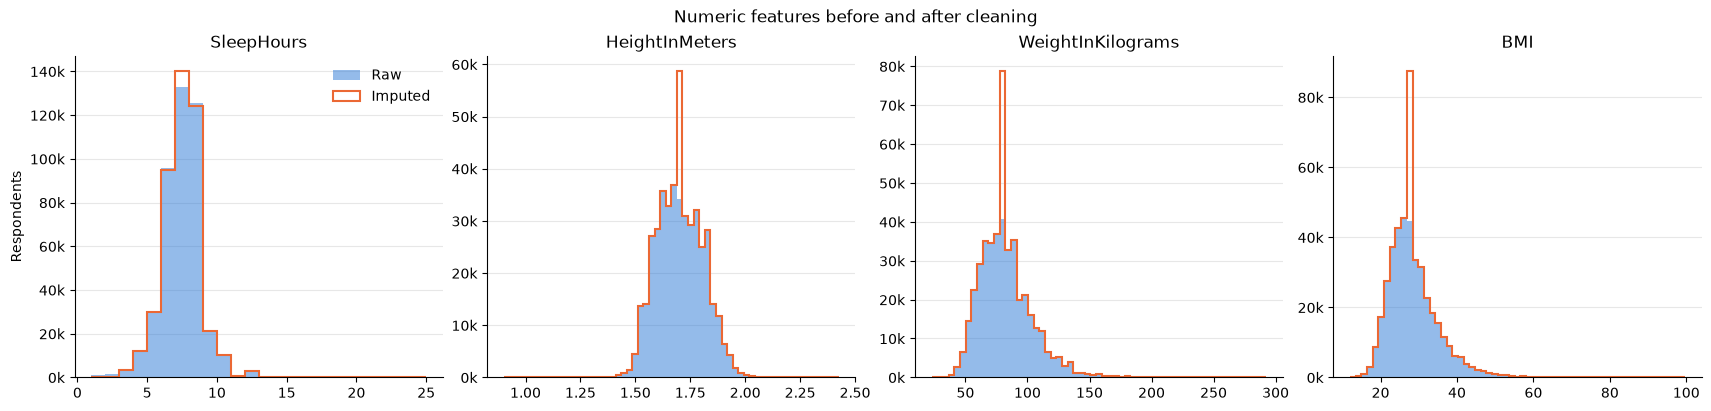

In [42]:
compare_cols = ["SleepHours", "HeightInMeters", "WeightInKilograms", "BMI"]
# Heights were recorded in whole inches, so height bins are one inch wide and centred on each inch
compare_bins = {
    "SleepHours": range(1, 26),
    "HeightInMeters": (np.arange(35, 96) + 0.5) * 0.0254,
    "WeightInKilograms": 60,
    "BMI": 60,
}

fig, axes = plt.subplots(1, 4, figsize=(17, 4), layout="constrained")
for ax, col in zip(axes, compare_cols):
    bins = compare_bins[col]
    if isinstance(bins, int):
        bins = np.linspace(df[col].min(), df[col].max(), bins)
    ax.hist(df[col].dropna(), bins=bins, color="#2a78d6", alpha=0.5, label="Raw")
    ax.hist(imputed_df[col], bins=bins, histtype="step", color="#eb6834", linewidth=1.5, label="Imputed")
    ax.set_title(col)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y / 1000:.0f}k")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Respondents")
axes[0].legend(frameon=False)
fig.suptitle("Numeric features before and after cleaning")

fig.savefig("figures/eda/raw_vs_cleaned_distributions.png", dpi=200)
plt.show()

In [43]:
# Filling blanks with the median piles values onto that one number: this is the spike in the histograms
pd.DataFrame({
    "median": imputed_df[compare_cols].median(),
    "raw values at median": [(df[c] == imputed_df[c].median()).sum() for c in compare_cols],
    "imputed values at median": [(imputed_df[c] == imputed_df[c].median()).sum() for c in compare_cols],
    "raw range": [f"{df[c].min():g}–{df[c].max():g}" for c in compare_cols],
    "imputed range": [f"{imputed_df[c].min():g}–{imputed_df[c].max():g}" for c in compare_cols],
})

,median,raw values at median,imputed values at median,raw range,imputed range
SleepHours,7.00,132927,140019,1–24,3–16
HeightInMeters,1.70,34038,58564,0.91–2.41,1.2–2.18
WeightInKilograms,80.74,2004,39924,22.68–292.57,30–250
BMI,27.44,3128,45831,12.02–99.64,13–70


### Findings

- **Every problem the EDA flagged is fixed.** Out-of-range values drop from 3,724 to 0, rows with 20+ blanks from 4,047 to 0, and there are no missing values left. Sleep now ranges 3–16 hours instead of 1–24, and height 1.2–2.2 m instead of 0.91–2.41 m.
- **Little data is lost.** 99.0% of rows are kept (440,778 of 445,132), and the heart disease rate is unchanged at 9.0%, so cleaning didn't bias the class balance.
- **Imputation has side effects:**
  - **Spikes at the median.** Tens of thousands of blank values are set to the same number: values at the median BMI go from about 3,100 to 45,800, and at the median weight from about 2,000 to 39,900. This shows up as a spike in the histograms and shrinks the spread.
  - **BMI no longer matches height and weight** in about 19,000 rows (4%), because the three columns are filled independently (e.g. a blank weight gets the median weight, but the real BMI is kept). This was accepted because BMI is largely redundant with weight.
  - **Duplicates.** Exact duplicates fall from 161 to 75 rather than 0: respondents whose blanks were filled with the same values can become identical.